# **Analisis Segmentasi Negara dan Pembangunan Ekonomi**

## **1.0 Bussines Understanding**

Sebuah lembaga bantuan internasional dan analis kebijakan global ingin
membangun sistem kecerdasan buatan berbasis Unsupervised Machine Learning untuk
mengelompokkan status sosio-ekonomi dan kesehatan dari berbagai negara di seluruh
dunia secara otomatis ke dalam beberapa klaster kelompok pembangunan tanpa perlu
melakukan penilaian manual satu per satu.
Dataset ini telah merekam berbagai indikator penting kesehatan, kesejahteraan sosial, dan
ekonomi makro, di mana setiap sampel direpresentasikan oleh profil negara tertentu. Tim
analis bertugas membangun model machine learning berbasis K-Means++ Clustering
untuk mempartisi data sampel ke dalam K klaster berdasarkan kemiripan tingkat mortalitas
anak, pendapatan per kapita, inflasi, dan produk domestik bruto yang terkandung di dalam
tiap baris data.

## **1.1 Latar Belakang**

Sebuah lembaga ingin membangun sistem untuk mengelompokkan status sosial ekonomi dan kesehatan dar berbagai negara secara otomatis.

## **1.2 Tujuan**

Membangun machine learning untuk memprediksi secara otomatis tanpa perlu melakukan penilaian secara manual

## **1.3 Masalah**

Dalam proses mengelompokkan masih menggunakan cara manual sehingga membuang waktu lama dan tidak efisien.

## **1.4 Solusi**

Solusinya yaitu dengan membangun machine learning untuk mengatasi dalam pengelompokkan ini agar dilakukan secara otomatis.

## **1.5 Deksripsi Kolom**

**1. Ukuran Data: 167 baris (mewakili 167 negara) dan 10 kolom.**


**2.  Fitur Input (X): Kolom atribut sosio-ekonomi dan kesehatan negara, yang meliputi:**
- country: Nama negara (string / teks).
- child_mort: Angka kematian anak di bawah usia 5 tahun per 1.000 kelahiran
hidup.
- exports: Persentase ekspor barang dan jasa terhadap PDB (GDP).
- health: Persentase pengeluaran total kesehatan terhadap PDB (GDP).
- imports: Persentase impor barang dan jasa terhadap PDB (GDP).
- income: Pendapatan bersih per kapita (satuan: USD)
- inflation: Tingkat pertumbuhan tahunan total inflasi dari PDB.
- life_expec: Rata-rata angka harapan hidup saat lahir (satuan: Tahun).
- total_fer: Angka kesuburan total / rata-rata jumlah anak yang dilahirkan oleh
seorang wanita.
- gdpp: Produk Domestik Bruto per kapita (satuan: USD per orang).


**3. Target Label (Y): Tidak ada label target (karena menggunakan pembelajaran tanpa**
**pengawasan / unsupervised learning), di mana algoritma bertugas menemukan**
**kelompok klaster pembangunan secara mandiri.**

## **2.0 Data Preparation**

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tkinter as tk

In [16]:
# df = pd.read_csv('Country-data.csv')
df = pd.read_csv('../dataset/Country-data.csv')
df.head(10)

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.440,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.490,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.100,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.400,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.440,76.8,2.13,12200
5,Argentina,14.5,18.9,8.10,16.0,18700,20.900,75.8,2.37,10300
6,Armenia,18.1,20.8,4.40,45.3,6700,7.770,73.3,1.69,3220
7,Australia,4.8,19.8,8.73,20.9,41400,1.160,82.0,1.93,51900
8,Austria,4.3,51.3,11.00,47.8,43200,0.873,80.5,1.44,46900
9,Azerbaijan,39.2,54.3,5.88,20.7,16000,13.800,69.1,1.92,5840


In [17]:
df.info()
df.describe()
df.size

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 13.2 KB


1670

Pada dataset ini memiliki 167 baris dan 10 kolom, dimana dengan tipe data numerik(float dan int) dan juga terdapat kolom string di kolom coutry. Daatset ini memiliki 1670 frame size.

In [18]:
df.isna().sum()

country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(0)

Dataset ini tidak memiliki data yang duplicate dan data yang kosong jadi data ini termasuk bersih dan tidak ada penanganan data kosong dan data duplikat.

## **3.0 Exploratory Data Analysis**

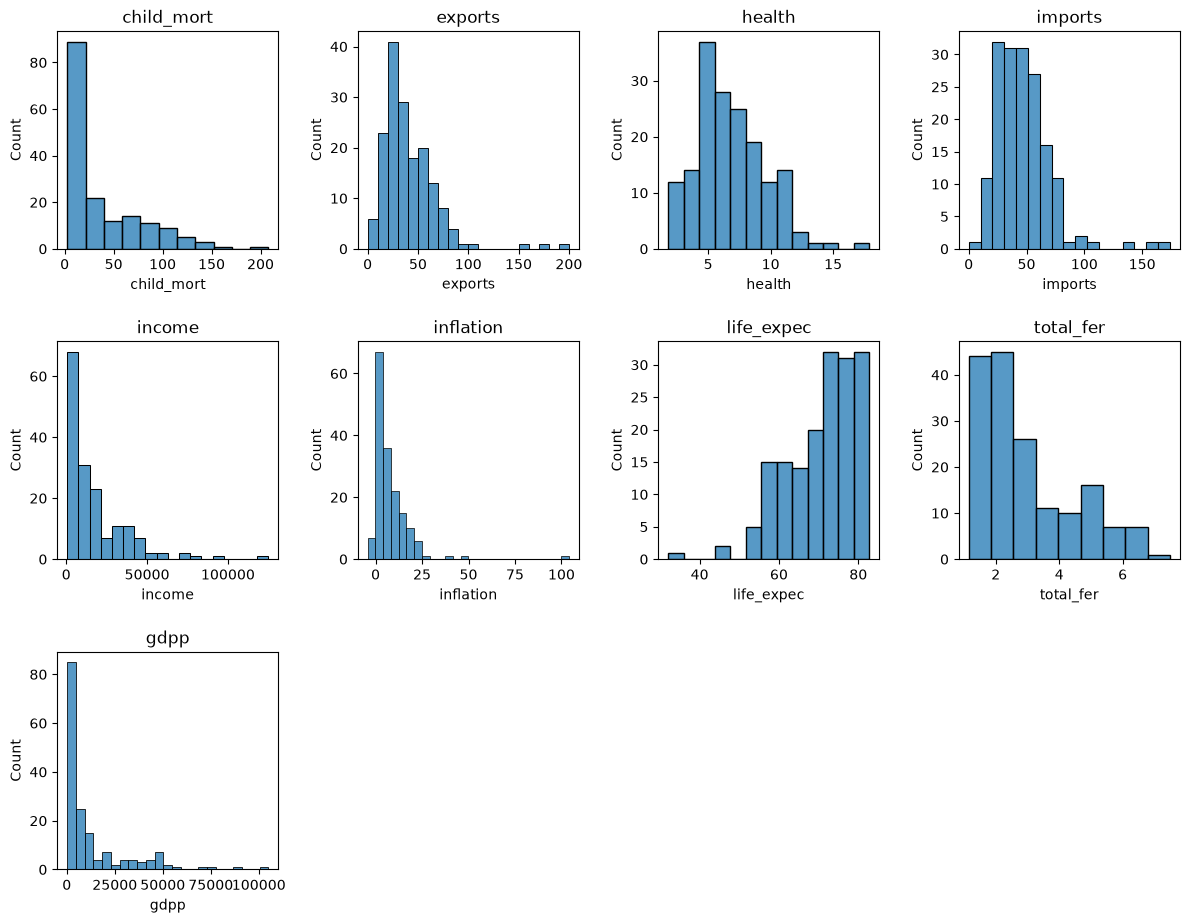

In [20]:
cols = df.select_dtypes(include=['number']).columns
 
plt.figure(figsize=(12, 12))

for i, col in enumerate(cols):
    plt.subplot(4, 4, i+1)
    sns.histplot(df[col])
    plt.title(col)

plt.tight_layout(h_pad=2, w_pad=2)
plt.show()

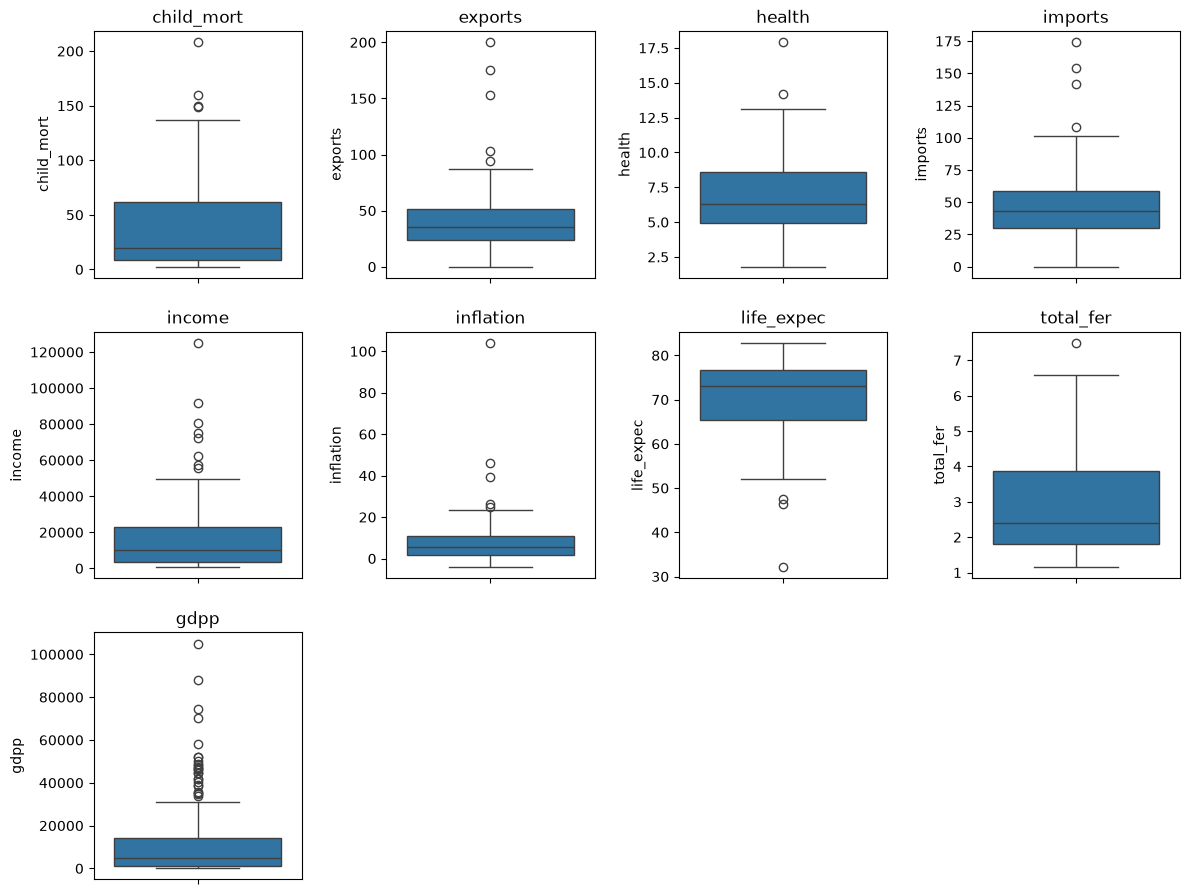

In [21]:
cols = df.select_dtypes(include=['number']).columns
 
plt.figure(figsize=(12, 12))

for i, col in enumerate(cols):
    plt.subplot(4, 4, i+1)
    sns.boxplot(df[col])
    plt.title(col)

plt.tight_layout(h_pad=2, w_pad=2)
plt.show()

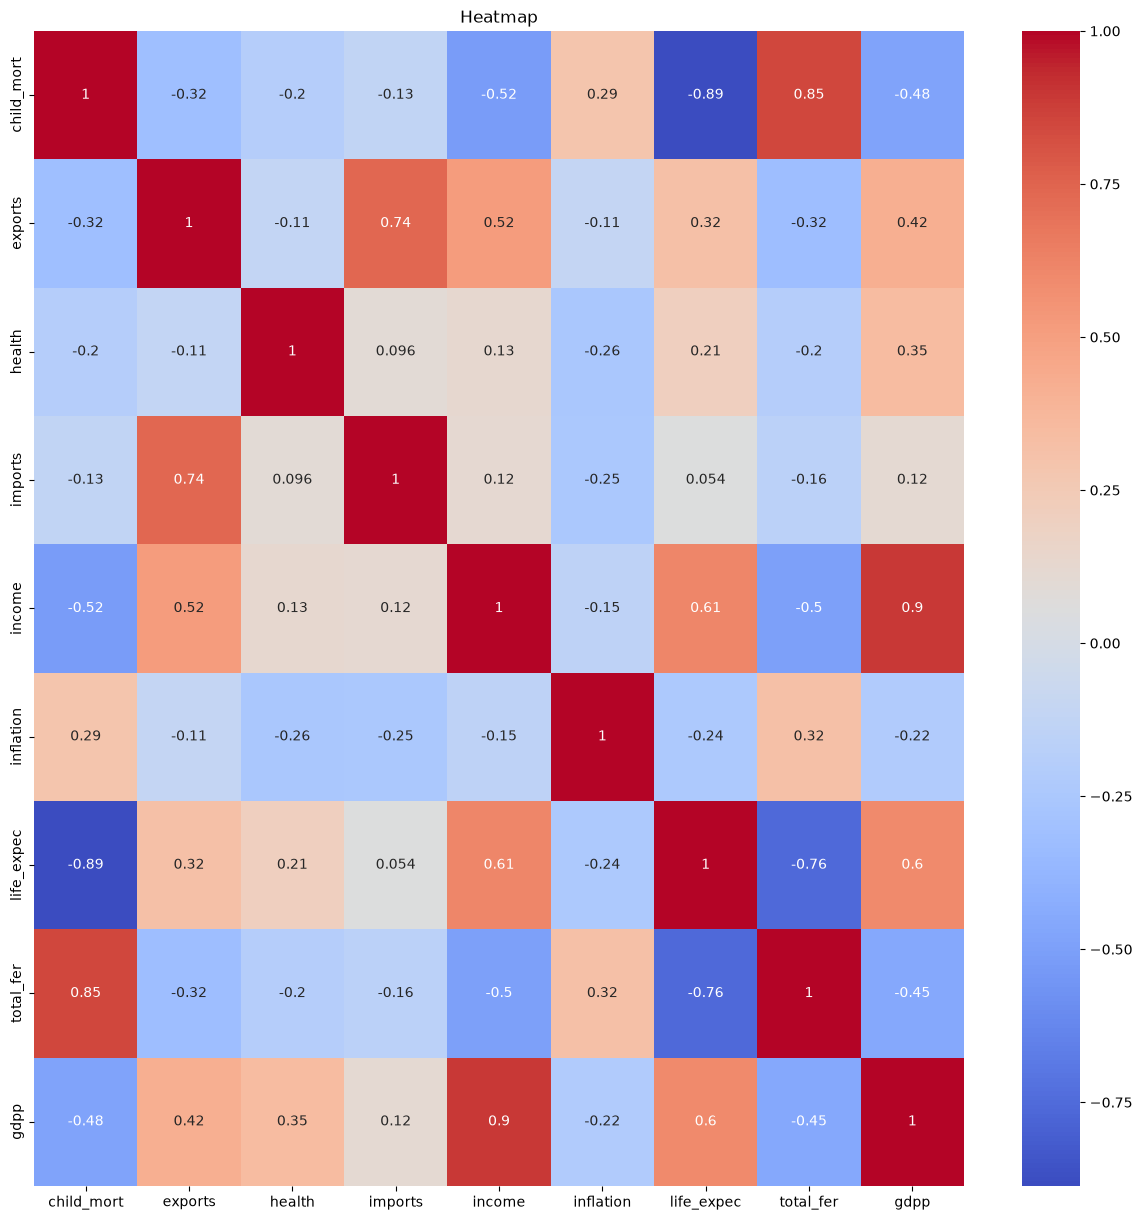

In [ ]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(15,15))
sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm')
plt.title('Heatmap')
plt.show()

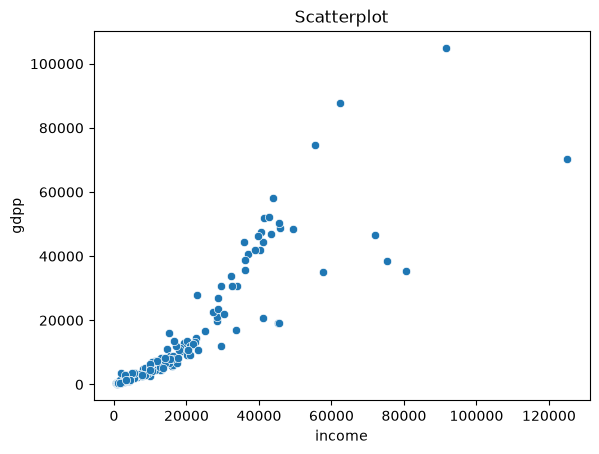

In [ ]:
sns.scatterplot(x='income', y='gdpp', data=df)
plt.title('Scatterplot')
plt.show()

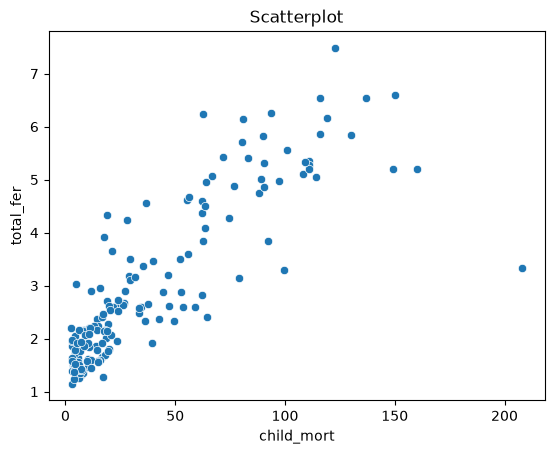

In [ ]:
sns.scatterplot(x='child_mort', y='total_fer', data=df)
plt.title('Scatterplot')
plt.show()

In [23]:
cols = df.select_dtypes(include=['number']).columns

q1 = df[cols].quantile(0.25)
q3 = df[cols].quantile(0.75)

iqr = q3 - q1

bb = q1 - 1.5 * iqr
bt = q3 + 1.5 * iqr

outlier = ((df[cols] < bb) | (df[cols] > bt)).sum()
print(outlier)
print(outlier.sum())

child_mort     4
exports        5
health         2
imports        4
income         8
inflation      5
life_expec     3
total_fer      1
gdpp          25
dtype: int64
57


Pada dataset ini persebaran data yang dimiliki itu tidak normal. Kemudian terdapat outlier pada semua kolom dan tertinggi yaitu kolom gdpp dan akan dilakukan penanganan outlier cappping. 

## **4.0 Data Preprocessing**

In [25]:
df_clipped = df[cols].clip(lower=bb, upper=bt, axis=1)

outlier = ((df_clipped[cols] < bb) | (df_clipped[cols] > bt)).sum()
print(outlier)
print(outlier.sum())

child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64
0


In [ ]:
country = df['country']

X = df[['child_mort', 'income', 'inflation', 'gdpp']]

Disini saya melakukan pemisahan fitur pada kolom negara dan X karena kolom negara jika di encoding maka sangat tidak mungkin dikarenakan nantinya banyak sekali kolomnya.

In [26]:
X = df[['child_mort', 'income', 'inflation', 'gdpp']].to_numpy()

mean = np.mean(X, axis=0)
std = np.std(X, axis=0)

X_scaled = (X - mean) / std

X_scaled[:5]

array([[ 1.29153238, -0.8082454 ,  0.15733622, -0.67917961],
       [-0.5389489 , -0.3753689 , -0.31234747, -0.48562324],
       [-0.27283273, -0.22084447,  0.78927429, -0.46537561],
       [ 2.00780766, -0.58504345,  1.38705353, -0.51626829],
       [-0.69563412,  0.10173177, -0.60174853, -0.04181713]])

Dan disini terdapat standarisasi data supaya dalam perhitungan jarak dengan skala yang seimbang

In [ ]:

print("Mean setelah scaling:")
print(np.mean(X_scaled, axis=0))

print("Standar deviasi setelah scaling:")
print(np.std(X_scaled, axis=0)) 

Mean setelah scaling:
[-3.72290356e-17 -7.97765048e-17 -1.06368673e-17  5.85027702e-17]
Standar deviasi setelah scaling:
[1. 1. 1. 1.]


In [33]:
root = tk.Tk()

root.title('Prediksi Pengolompokkan Negara')
root.geometry('800x600')
root.configure(bg='white')

judul = tk.Label(
    root,
    text='Country Clustering',
    font=('Poppins', 20, 'bold'),
    bg="#F4F6F9",
    fg="#1E293B"
)
judul.pack(pady=20)

root.mainloop()